In [1]:
import sys
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
from tqdm import tqdm
from matplotlib.ticker import FuncFormatter, MultipleLocator

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_v2 import Moire
import utils

### Initialize system

In [6]:
sys = Moire(theta_deg=1.0, psi_deg=50.0, V=3.0, n_shells=10)

### Compare analytics: Harmonic approximation vs. perturbed

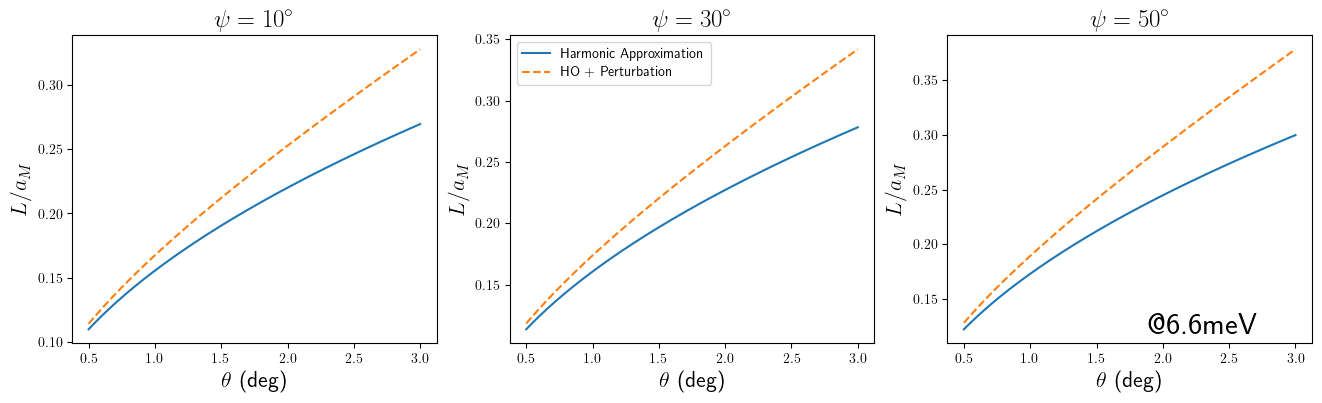

In [4]:
thetas = np.linspace(0.5, 3, 1000)
aMs = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sys.psi_deg = 10.0
ax[0].plot(thetas, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs)
ax[0].plot(thetas, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--')
ax[0].set_xlabel(r'$\theta$ (deg)', fontsize=16)
ax[0].set_title(r'$\psi = 10^\circ$', fontsize=18)
ax[0].set_ylabel(r'$L / a_M$', fontsize=16)
#ax[0].set_ylim(0, 0.5)

sys.psi_deg = 30.0
ax[1].plot(thetas, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs, label='Harmonic Approximation')
ax[1].plot(thetas, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--', label='HO + Perturbation')
ax[1].set_xlabel(r'$\theta$ (deg)', fontsize=16)
ax[1].set_title(r'$\psi = 30^\circ$', fontsize=18)
ax[1].set_ylabel(r'$L / a_M$', fontsize=16)
#ax[1].set_ylim(0, 0.5)
ax[1].legend()

sys.psi_deg = 50.0
ax[2].plot(thetas, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs)
ax[2].plot(thetas, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--')
ax[2].set_xlabel(r'$\theta$ (deg)', fontsize=16)
ax[2].set_title(r'$\psi = 50^\circ$', fontsize=18)
ax[2].set_ylabel(r'$L / a_M$', fontsize=16)
#ax[2].set_ylim(0, 0.5)
ax[2].text(0.7, 0.1, "@" + str(sys.V) + "meV", 
           transform=ax[2].transAxes, fontsize=22, fontweight='bold', va='top', ha='center')

plt.show()

### Analytics vs. Wannier

#### Harmonic and Perturbed Ground states

##### Large $\psi=50^\circ$

Text(0.5, 1.0, '$\\Delta(\\mathbf{r})$')

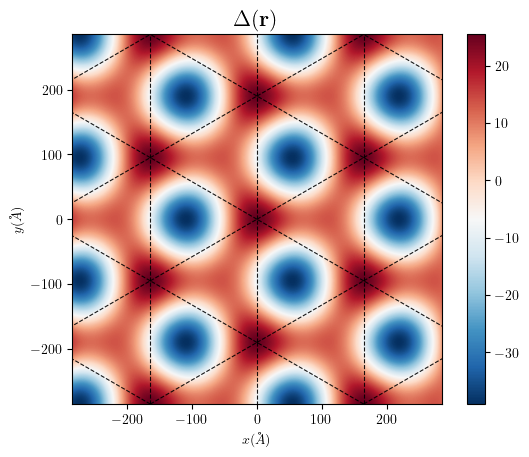

In [5]:
sys.psi_deg = 50.0
sys.V = 6.6
scale = 1.5

fig, ax = plt.subplots()
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
im = sys.plot_moire_potential(ax, extent, resolution=400)
fig.colorbar(im, ax=ax)
sys.plot_triangular_lattice(ax, extent)

ax.set_xlabel(r'$x (\AA)$')
ax.set_ylabel(r'$y (\AA)$')
ax.set_title(r'$\Delta(\mathbf{r})$', fontsize=16)

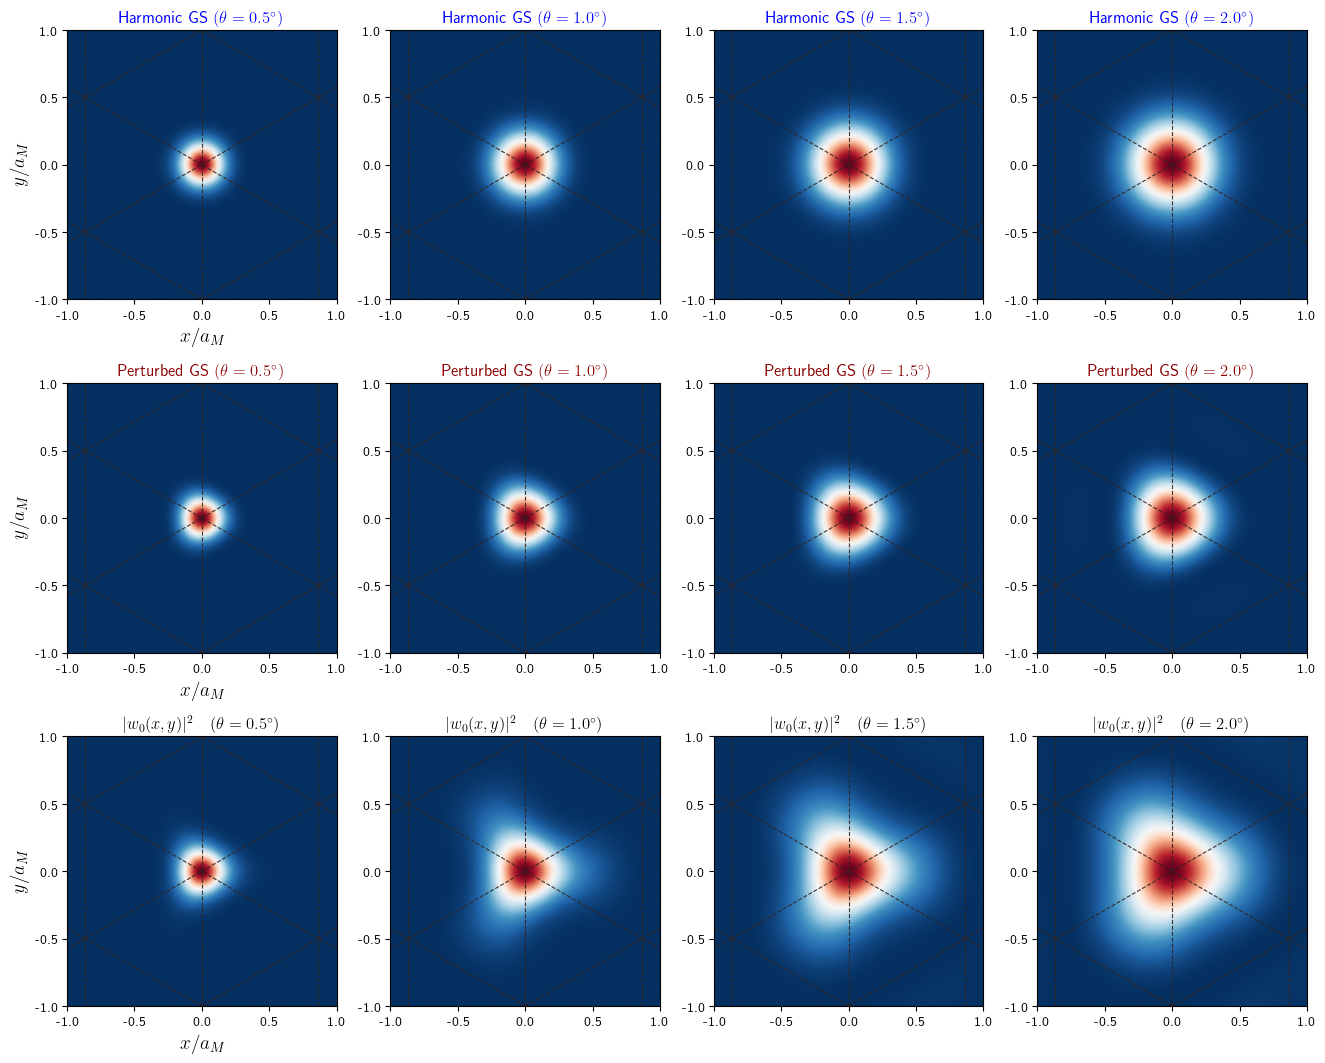

In [10]:
scale = 1.0
Nx = 100
Ny = 100

thetas = [0.5, 1.0, 1.5, 2.0]

fig, ax = plt.subplots(3, len(thetas), figsize=(16, 13))
norm = None

for i in range(len(thetas)):
    sys.theta_deg = thetas[i]
    aM_i = sys.aM
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)

    psi_ho = utils.ho_2d_groundstate(X, Y, sys.aM, sys.V, sys.psi)
    psi_ho_perturbed = utils.ho_2d_groundstate_perturbed(X, Y, sys.aM, sys.V, sys.psi)

    # Compute global limits first (recommended)
    # all_data = []
    # all_data.extend([
    #     np.abs(psi_ho)**2,
    #     np.abs(psi_ho_perturbed)**2
    # ])
    # vmin = min(d.min() for d in all_data)
    # vmax = max(d.max() for d in all_data)

    # norm = Normalize(vmin=vmin, vmax=vmax)

    im = ax[0, i].imshow(
        np.abs(psi_ho) ** 2,
        extent=[x.min(), x.max(), y.min(), y.max()],
        origin='lower',
        cmap='RdBu_r',
        norm=norm,
        interpolation='bilinear'
    )
    #fig.colorbar(im, ax=ax, label=r'$|\psi_{0,0}(x, y)|^2$')
    #ax[0, i].set_xlabel(r'$x\, (\AA)$')
    #ax[0, i].set_ylabel(r'$y\, (\AA)$')
    ax[0, i].set_title(r"Harmonic GS $(\theta = " + str(thetas[i]) + r"^\circ)$", color='blue')
    sys.plot_triangular_lattice(ax[0, i], extent=[x.min(), x.max(), y.min(), y.max()])

    ax[0, i].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
    ax[0, i].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
    ax[0, i].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
    ax[0, i].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
    ax[0, 0].set_xlabel(r'$x/a_M$', fontsize=14)
    ax[0, 0].set_ylabel(r'$y/a_M$', fontsize=14)

    im2 = ax[1, i].imshow(
        np.abs(psi_ho_perturbed) ** 2,
        extent=[x.min(), x.max(), y.min(), y.max()],
        origin='lower',
        cmap='RdBu_r',
        norm=norm,
        interpolation='bilinear'
    )
    #fig.colorbar(im2, ax=ax[1], label=r'$|\psi(x, y)|^2$')
    #ax[1, i].set_xlabel(r'$x\, (\AA)$')
    #ax[1, i].set_ylabel(r'$y\, (\AA)$')
    ax[1, i].set_title(r"Perturbed GS $(\theta = " + str(thetas[i]) + r"^\circ)$", color='darkred')
    sys.plot_triangular_lattice(ax[1, i], extent=[x.min(), x.max(), y.min(), y.max()])
    ax[1, i].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
    ax[1, i].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
    ax[1, i].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
    ax[1, i].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
    ax[1, 0].set_xlabel(r'$x/a_M$', fontsize=14)
    ax[1, 0].set_ylabel(r'$y/a_M$', fontsize=14)

    k_points = sys.mesh_k_unit_cell()
    sys.plot_wannier_function(ax[2, i], X, Y, k_points, norm=norm)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[2, i], extent)

    ax[2, i].xaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
    ax[2, i].yaxis.set_major_formatter(FuncFormatter(lambda val, pos, L=aM_i: f'{val/L:.1f}'))
    ax[2, i].xaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
    ax[2, i].yaxis.set_major_locator(MultipleLocator(0.5 * aM_i))
    ax[2, 0].set_xlabel(r'$x/a_M$', fontsize=14)
    ax[2, 0].set_ylabel(r'$y/a_M$', fontsize=14)
    ax[2, i].set_title(r'$|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

plt.savefig("plots/gs_wannier.pdf", dpi=300, bbox_inches='tight')
    

##### Small $\psi=26^\circ$

Text(0.5, 1.0, '$\\Delta(\\mathbf{r})$')

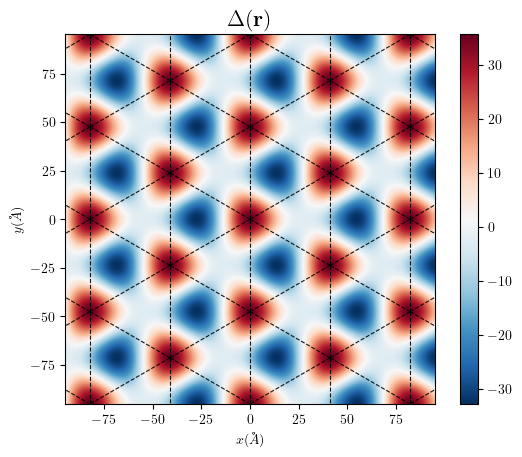

In [12]:
sys.psi_deg = 26.0
sys.V = 6.6
scale = 1.5

fig, ax = plt.subplots()
scale = 2.0
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
im = sys.plot_moire_potential(ax, extent, resolution=400)
fig.colorbar(im, ax=ax)
sys.plot_triangular_lattice(ax, extent)

ax.set_xlabel(r'$x (\AA)$')
ax.set_ylabel(r'$y (\AA)$')
ax.set_title(r'$\Delta(\mathbf{r})$', fontsize=16)

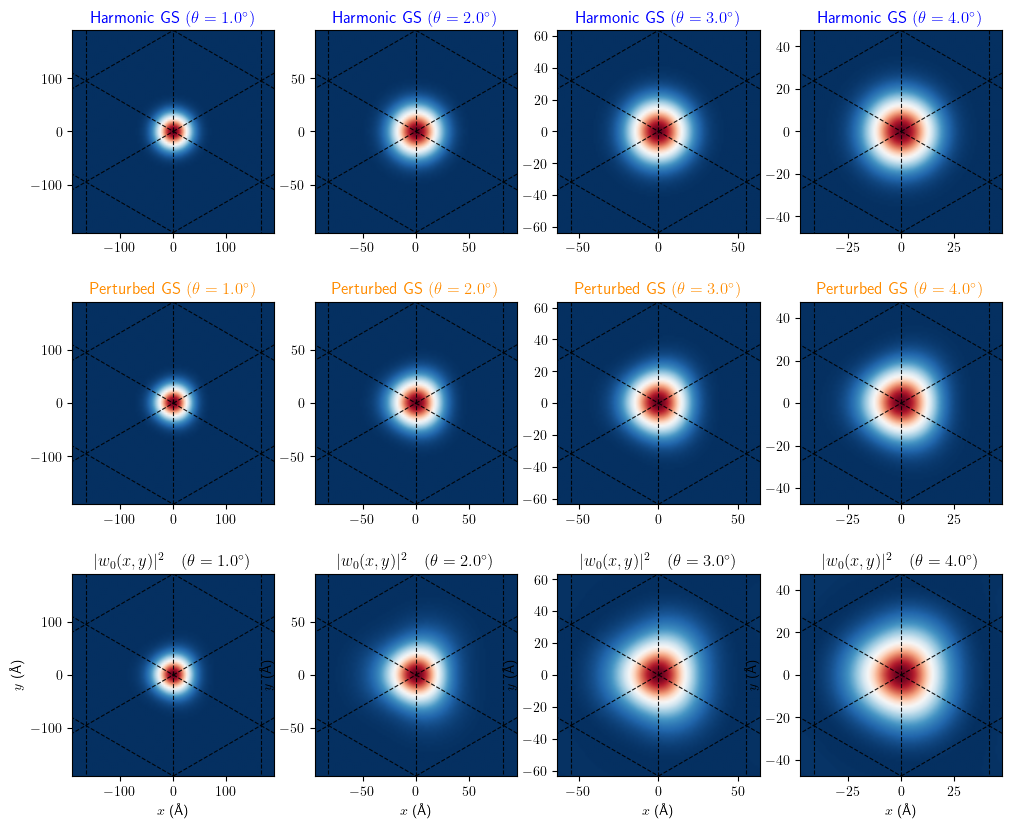

In [13]:
scale = 1.0
Nx = 100
Ny = 100

thetas = [1.0, 2.0, 3.0, 4.0]

fig, ax = plt.subplots(3, len(thetas), figsize=(12, 10))

for i in range(len(thetas)):
    sys.theta_deg = thetas[i]
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)

    psi_ho = utils.ho_2d_groundstate(X, Y, sys.aM, sys.V, sys.psi)
    psi_ho_perturbed = utils.ho_2d_groundstate_perturbed(X, Y, sys.aM, sys.V, sys.psi)

    im = ax[0, i].imshow(
        np.abs(psi_ho) ** 2,
        extent=[x.min(), x.max(), y.min(), y.max()],
        origin='lower',
        cmap='RdBu_r',
        interpolation='bilinear'
    )
    #fig.colorbar(im, ax=ax, label=r'$|\psi_{0,0}(x, y)|^2$')
    #ax[0, i].set_xlabel(r'$x\, (\AA)$')
    #ax[0, i].set_ylabel(r'$y\, (\AA)$')
    ax[0, i].set_title(r"Harmonic GS $(\theta = " + str(thetas[i]) + r"^\circ)$", color='blue')
    sys.plot_triangular_lattice(ax[0, i], extent=[x.min(), x.max(), y.min(), y.max()])

    im2 = ax[1, i].imshow(
        np.abs(psi_ho_perturbed) ** 2,
        extent=[x.min(), x.max(), y.min(), y.max()],
        origin='lower',
        cmap='RdBu_r',
        interpolation='bilinear'
    )
    #fig.colorbar(im2, ax=ax[1], label=r'$|\psi(x, y)|^2$')
    #ax[1, i].set_xlabel(r'$x\, (\AA)$')
    #ax[1, i].set_ylabel(r'$y\, (\AA)$')
    ax[1, i].set_title(r"Perturbed GS $(\theta = " + str(thetas[i]) + r"^\circ)$", color='darkorange')
    sys.plot_triangular_lattice(ax[1, i], extent=[x.min(), x.max(), y.min(), y.max()])

    k_points = sys.mesh_k_unit_cell()
    sys.plot_wannier_function(ax[2, i], X, Y, k_points)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[2, i], extent)

    ax[2, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[2, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[2, i].set_title(r'$|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

### Wannier functions near the origin

Norm of Wannier function:  0.9999999974627246 | theta = 1.0
Norm of Wannier function:  0.9994641843354972 | theta = 2.0
Norm of Wannier function:  0.9921776738217667 | theta = 3.0


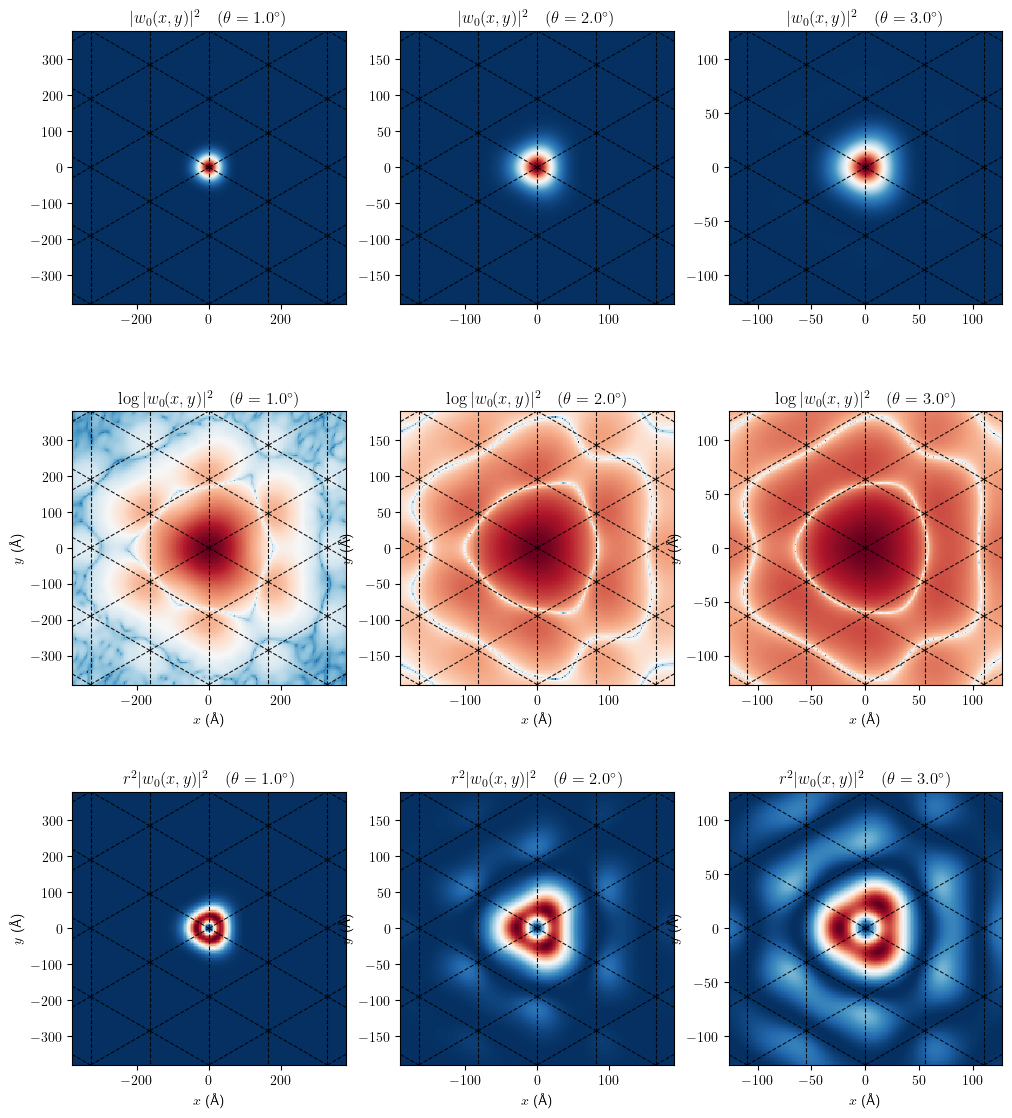

In [14]:
sys.psi_deg = 26.0
sys.V = 6.6
sys.n_shells = 9
scale = 2.0

Nx = 200
Ny = 200

thetas = [1.0, 2.0, 3.0]

fig, ax = plt.subplots(3, len(thetas), figsize=(12, 14))

for i in range(len(thetas)):
    sys.theta_deg = thetas[i]
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)

    k_points = sys.mesh_k_unit_cell()

    k_points = sys.mesh_k_unit_cell()
    sys.plot_wannier_function(ax[0, i], X, Y, k_points)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[0, i], extent)
    ax[0, i].set_title(r'$|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

    wannier = sys.wannier_wavefunction(X, Y, k_points, gauge_fixed=True)
    fun = lambda x, y: 1
    print("Norm of Wannier function: ", sys.integrate_wannier(fun, X, Y, k_points), "| theta =", thetas[i])
    density = np.abs(wannier)**2

    ax[1, i].imshow(np.log(density), extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')

    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[1, i], extent)

    ax[1, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[1, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[1, i].set_title(r'$\log|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

    R2 = X**2 + Y**2
    ax[2, i].imshow(R2 * density, extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')

    sys.plot_triangular_lattice(ax[2, i], extent)

    ax[2, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[2, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[2, i].set_title(r'$r^2|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

#### Wannier functions at large scale

Norm of Wannier function:  0.9999999998147274 | theta = 1.0
Norm of Wannier function:  0.9999999992265817 | theta = 2.0
Norm of Wannier function:  0.9999899512425435 | theta = 3.0


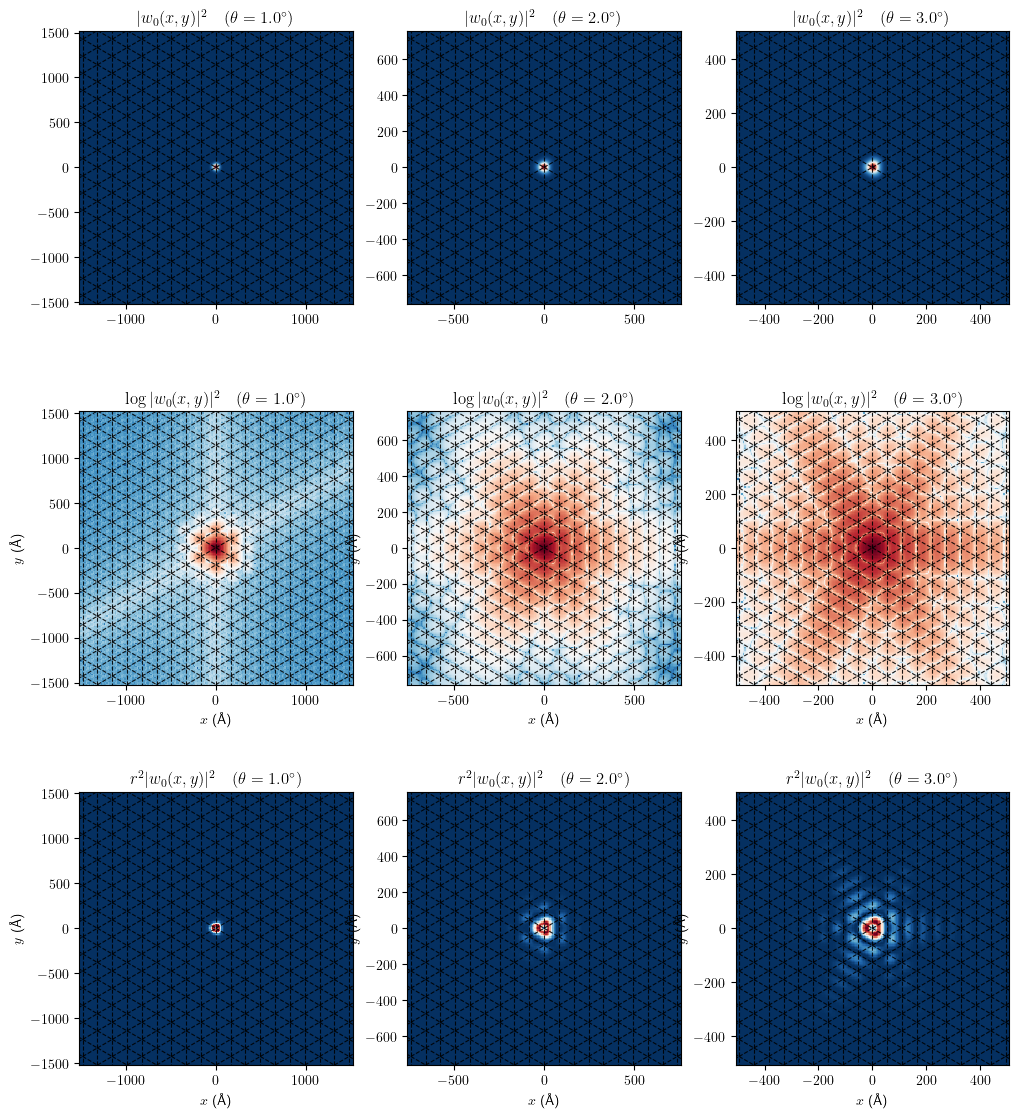

In [15]:
scale = 8.0

Nx = 200
Ny = 200

thetas = [1.0, 2.0, 3.0]

fig, ax = plt.subplots(3, len(thetas), figsize=(12, 14))

for i in range(len(thetas)):
    sys.theta_deg = thetas[i]
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)

    k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)
    sys.plot_wannier_function(ax[0, i], X, Y, k_points)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[0, i], extent)
    ax[0, i].set_title(r'$|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

    wannier = sys.wannier_wavefunction(X, Y, k_points, gauge_fixed=True)
    fun = lambda x, y: 1
    print("Norm of Wannier function: ", sys.integrate_wannier(fun, X, Y, k_points), "| theta =", thetas[i])
    density = np.abs(wannier)**2

    ax[1, i].imshow(np.log(density), extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')

    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[1, i], extent)

    ax[1, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[1, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[1, i].set_title(r'$\log|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

    R2 = X**2 + Y**2
    ax[2, i].imshow(R2 * density, extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')

    sys.plot_triangular_lattice(ax[2, i], extent)

    ax[2, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[2, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[2, i].set_title(r'$r^2|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

## Comparison length scales

#### Large $V=30\text{meV}$

In [16]:
sys.psi_deg = 20.0
sys.V = 30.0
sys.n_shells = 10

Norm of Wannier function:  0.9999999524417583 | theta = 1.0
Norm of Wannier function:  0.9999999993678259 | theta = 1.5
Norm of Wannier function:  0.9999999999837272 | theta = 2.0


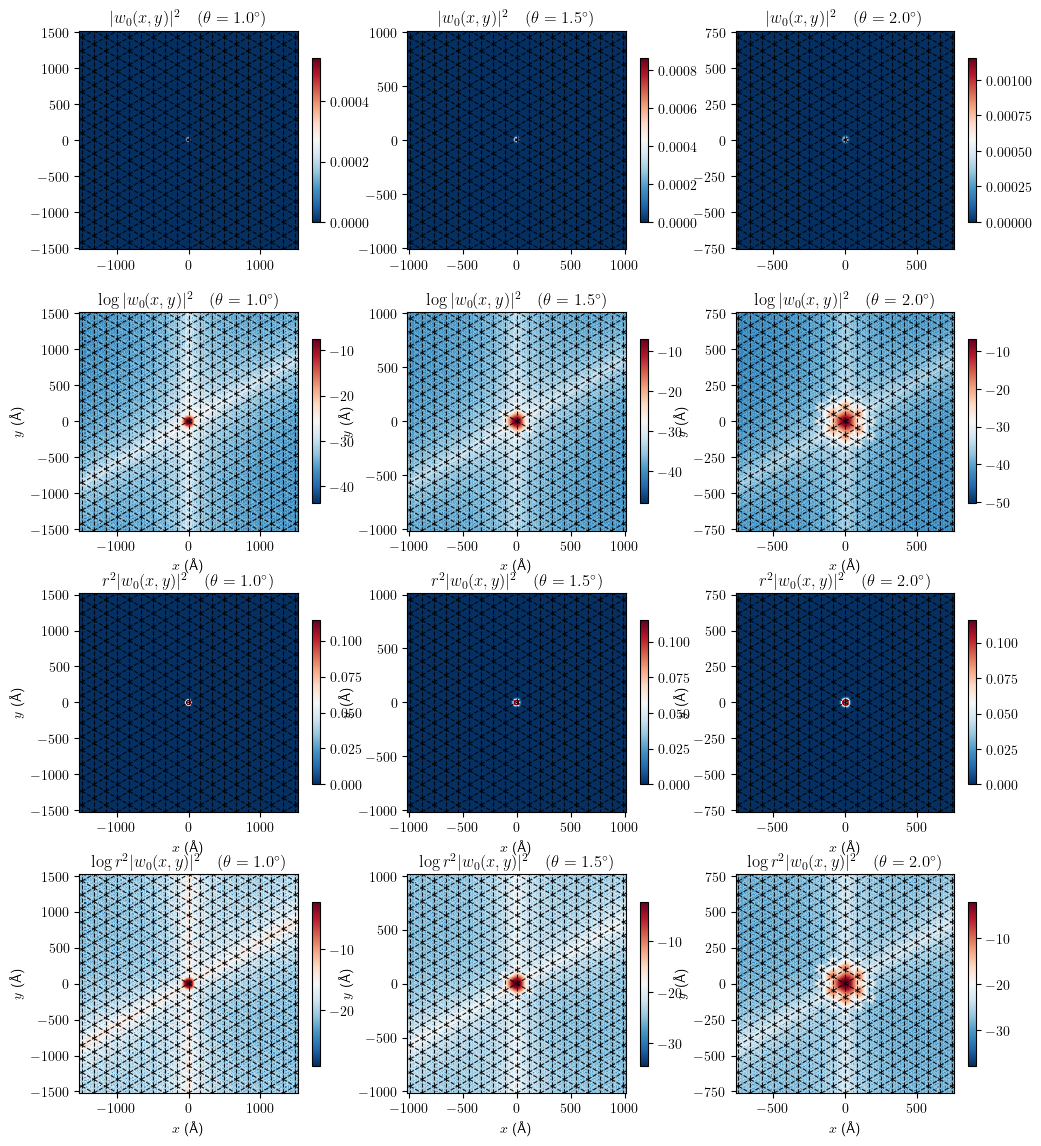

In [17]:
scale = 8.0

Nx = 200
Ny = 200

thetas = [1.0, 1.5, 2.0]

fig, ax = plt.subplots(4, len(thetas), figsize=(12, 14))

for i in range(len(thetas)):
    sys.theta_deg = thetas[i]
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)

    k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)
    im = sys.plot_wannier_function(ax[0, i], X, Y, k_points)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[0, i], extent)
    ax[0, i].set_title(r'$|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');
    cbar = fig.colorbar(im, ax=ax[0,i], shrink=0.7)

    wannier = sys.wannier_wavefunction(X, Y, k_points, gauge_fixed=True)
    fun = lambda x, y: 1
    print("Norm of Wannier function: ", sys.integrate_wannier(fun, X, Y, k_points), "| theta =", thetas[i])
    density = np.abs(wannier)**2

    im = ax[1, i].imshow(np.log(density), extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
    cbar = fig.colorbar(im, ax=ax[1, i], shrink=0.7)

    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[1, i], extent)

    ax[1, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[1, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[1, i].set_title(r'$\log|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

    R2 = X**2 + Y**2
    im = ax[2, i].imshow(R2 * density, extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
    cbar = fig.colorbar(im, ax=ax[2, i], shrink=0.7)

    sys.plot_triangular_lattice(ax[2, i], extent)

    ax[2, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[2, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[2, i].set_title(r'$r^2|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');
    
    im = ax[3, i].imshow(np.log(R2 * density), extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
    cbar = fig.colorbar(im, ax=ax[3, i], shrink=0.7)

    sys.plot_triangular_lattice(ax[3, i], extent)

    ax[3, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[3, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[3, i].set_title(r'$\log r^2|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

In [18]:
thetas = np.linspace(1.0, 2.0, 10)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
rW_values = []

Nx = 400
Ny = 400

for th in tqdm(thetas):
    sys.theta_deg = th

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    k_points = sys.mesh_k_unit_cell()

    fun = lambda x, y: x**2 + y**2
    rW = np.sqrt( sys.integrate_wannier(fun, X, Y, k_points) )
    rW_values.append(rW)

100%|██████████| 10/10 [03:48<00:00, 22.85s/it]


<>:11: SyntaxWarning: invalid escape sequence '\p'
<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:11: SyntaxWarning: invalid escape sequence '\p'
<>:11: SyntaxWarning: invalid escape sequence '\c'
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_3621/1718016309.py:11: SyntaxWarning: invalid escape sequence '\p'
  plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_3621/1718016309.py:11: SyntaxWarning: invalid escape sequence '\c'
  plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);


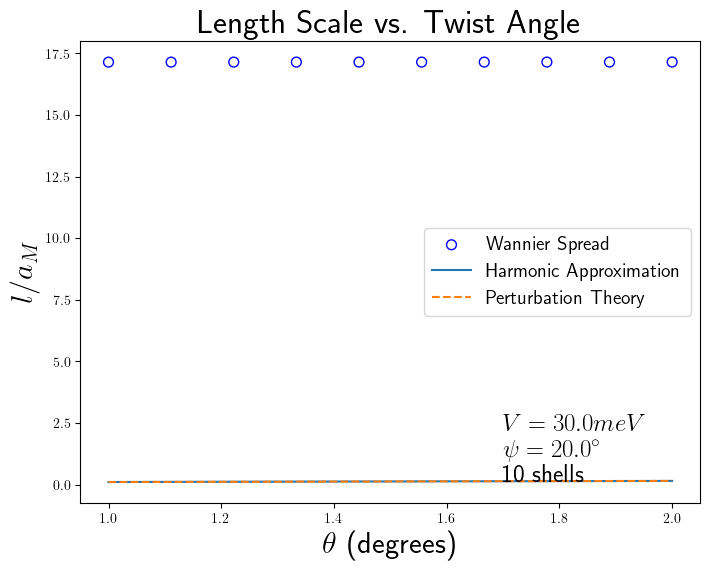

In [19]:
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

fig = plt.figure(figsize=(8, 6))
plt.scatter(thetas, np.array(rW_values) / aMs0, facecolors='none', edgecolors='blue', s=50, label='Wannier Spread')
plt.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs, label='Harmonic Approximation')
plt.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--', label='Perturbation Theory')
plt.xlabel(r'$\theta$ (degrees)', fontsize=22)
plt.ylabel(r'$l / a_M$', fontsize=22)
plt.title('Length Scale vs. Twist Angle', fontsize=24)
plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
plt.legend(fontsize=14)
plt.show()

### Small $V=6.6\text{meV}$

KeyboardInterrupt: 

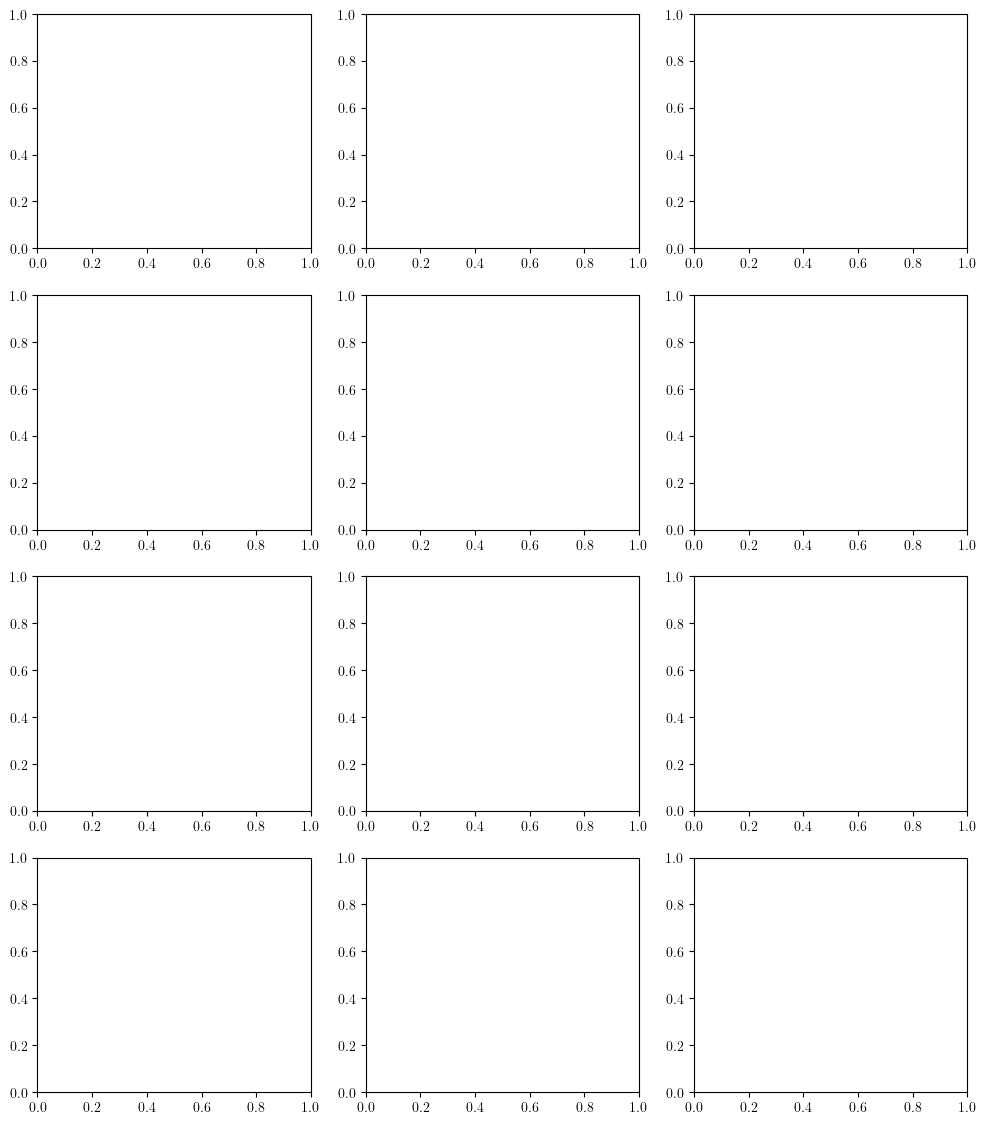

In [20]:
sys.V = 6.6
sys.n_shells = 12
scale = 8.0

Nx = 200
Ny = 200

thetas = [1.0, 1.5, 2.0]

fig, ax = plt.subplots(4, len(thetas), figsize=(12, 14))

for i in range(len(thetas)):
    sys.theta_deg = thetas[i]
    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)

    k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)
    im = sys.plot_wannier_function(ax[0, i], X, Y, k_points)
    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[0, i], extent)
    ax[0, i].set_title(r'$|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');
    cbar = fig.colorbar(im, ax=ax[0,i], shrink=0.7)

    wannier = sys.wannier_wavefunction(X, Y, k_points, gauge_fixed=True)
    fun = lambda x, y: 1
    print("Norm of Wannier function: ", sys.integrate_wannier(fun, X, Y, k_points), "| theta =", thetas[i])
    density = np.abs(wannier)**2

    im = ax[1, i].imshow(np.log(density), extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
    cbar = fig.colorbar(im, ax=ax[1, i], shrink=0.7)

    extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
    sys.plot_triangular_lattice(ax[1, i], extent)

    ax[1, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[1, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[1, i].set_title(r'$\log|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

    R2 = X**2 + Y**2
    im = ax[2, i].imshow(R2 * density, extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
    cbar = fig.colorbar(im, ax=ax[2, i], shrink=0.7)

    sys.plot_triangular_lattice(ax[2, i], extent)

    ax[2, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[2, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[2, i].set_title(r'$r^2|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');
    
    im = ax[3, i].imshow(np.log(R2 * density), extent=extent, origin='lower', 
                    interpolation='none', cmap='RdBu_r')
    cbar = fig.colorbar(im, ax=ax[3, i], shrink=0.7)

    sys.plot_triangular_lattice(ax[3, i], extent)

    ax[3, i].set_xlabel(r'$x$ (Å)', fontsize=10)
    ax[3, i].set_ylabel(r'$y$ (Å)', fontsize=10)
    ax[3, i].set_title(r'$\log r^2|w_0(x,y)|^2\quad(\theta = ' + str(thetas[i]) + r'^\circ)$', color='black');

In [ ]:
thetas = np.linspace(1.0, 2.0, 10)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
rW_values = []

Nx = 400
Ny = 400

for th in tqdm(thetas):
    sys.theta_deg = th

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    
    k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)

    fun = lambda x, y: x**2 + y**2
    rW = np.sqrt( sys.integrate_wannier(fun, X, Y, k_points) )
    rW_values.append(rW)

  0%|          | 0/10 [05:58<?, ?it/s]


KeyboardInterrupt: 

<>:11: SyntaxWarning: invalid escape sequence '\p'
<>:11: SyntaxWarning: invalid escape sequence '\c'
<>:11: SyntaxWarning: invalid escape sequence '\p'
<>:11: SyntaxWarning: invalid escape sequence '\c'
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2450/3335124169.py:11: SyntaxWarning: invalid escape sequence '\p'
  plt.text(1.7, 0.16, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2450/3335124169.py:11: SyntaxWarning: invalid escape sequence '\c'
  plt.text(1.7, 0.16, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);


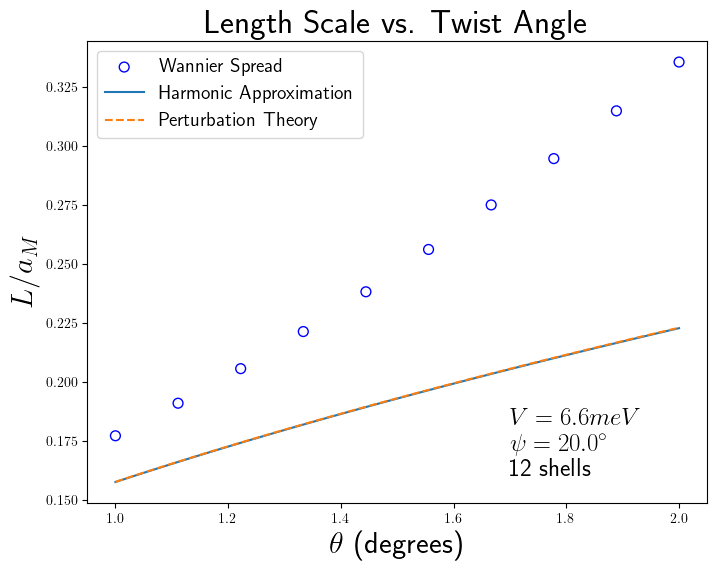

In [ ]:
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

fig = plt.figure(figsize=(8, 6))
plt.scatter(thetas, np.array(rW_values) / aMs0, facecolors='none', edgecolors='blue', s=50, label='Wannier Spread')
plt.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs, label='Harmonic Approximation')
plt.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--', label='Perturbation Theory')
plt.xlabel(r'$\theta$ (degrees)', fontsize=22)
plt.ylabel(r'$L / a_M$', fontsize=22)
plt.title('Length Scale vs. Twist Angle', fontsize=24)
plt.text(1.7, 0.16, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
plt.legend(fontsize=14)
plt.show()

## Trace of Metric

In [21]:
sys.psi_deg = 20.0
sys.V = 30.0
sys.n_shells = 10

Text(0, 0.5, '$k_y$')

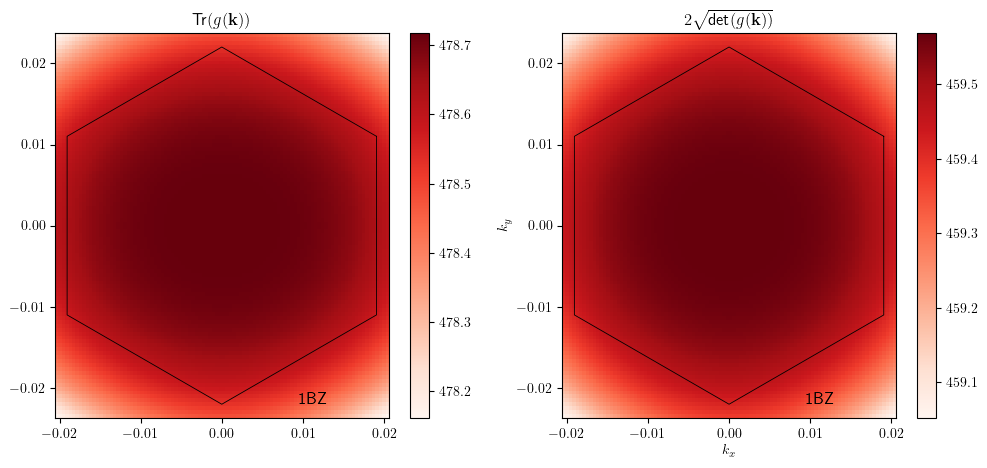

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
scale = 1.1
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 100)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 100)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric(ax, KX, KY)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')

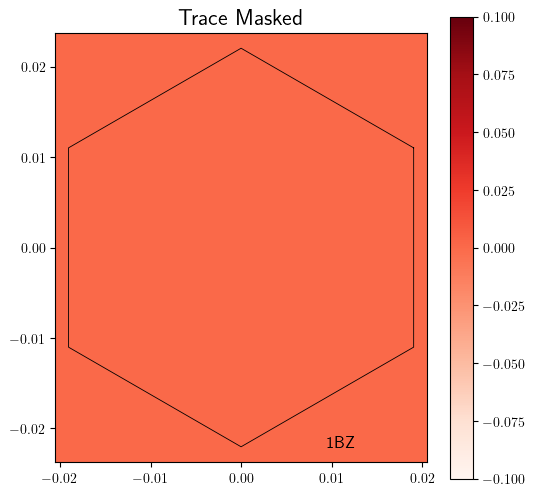

In [23]:
#trace_masked, mask, integral, KXX, KYY = sys.integrate_trace(KX, KY)
trace_masked, integral, KXX, KYY = sys.integrate_trace(KX, KY)
extent = [KXX.min(), KXX.max(), KYY.min(), KYY.max()]

lw = 0.6

fig, ax = plt.subplots(figsize=(6, 6))
im00 = ax.imshow(trace_masked, origin='lower', extent=extent, cmap='Reds')
ax.set_title(r"Trace Masked", fontsize=16)
sys.plot_hexagonal_bz(ax, lw=lw)
plt.colorbar(im00, ax=ax)

In [ ]:
KXX

array([[-0.02055333, -0.02012955, -0.01970577, ...,  0.01970577,
         0.02012955,  0.02055333],
       [-0.02055333, -0.02012955, -0.01970577, ...,  0.01970577,
         0.02012955,  0.02055333],
       [-0.02055333, -0.02012955, -0.01970577, ...,  0.01970577,
         0.02012955,  0.02055333],
       ...,
       [-0.02055333, -0.02012955, -0.01970577, ...,  0.01970577,
         0.02012955,  0.02055333],
       [-0.02055333, -0.02012955, -0.01970577, ...,  0.01970577,
         0.02012955,  0.02055333],
       [-0.02055333, -0.02012955, -0.01970577, ...,  0.01970577,
         0.02012955,  0.02055333]])

In [ ]:
sys.BZ_path

Path(array([[1.90701019e-02, 1.10101284e-02],
       [1.73472348e-18, 2.20202569e-02],
       [1.73472348e-18, 2.20202569e-02],
       [1.73472348e-18, 2.20202569e-02],
       [1.73472348e-18, 2.20202569e-02],
       [1.73472348e-18, 2.20202569e-02]]), None)

In [ ]:
thetas = np.linspace(1.0, 2.0, 10)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
rW_values = []
l0_values = []
scale_W = 6.0

Nx = 300
Ny = 300

for th in tqdm(thetas):
    sys.theta_deg = th

    x = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, Nx)
    y = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    k_points = sys.mesh_k_unit_cell(Nx=10, Ny=10)

    fun = lambda xx, yy: xx**2 + yy**2
    rW = np.sqrt( sys.integrate_wannier(fun, X, Y, k_points) )
    rW_values.append(rW)

    _, integral, _, _ = sys.integrate_trace(KX, KY)
    l0 = np.sqrt(integral)
    l0_values.append(l0)

100%|██████████| 10/10 [05:57<00:00, 35.72s/it]


<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\c'
<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\c'
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2834/423651878.py:12: SyntaxWarning: invalid escape sequence '\p'
  plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2834/423651878.py:12: SyntaxWarning: invalid escape sequence '\c'
  plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);


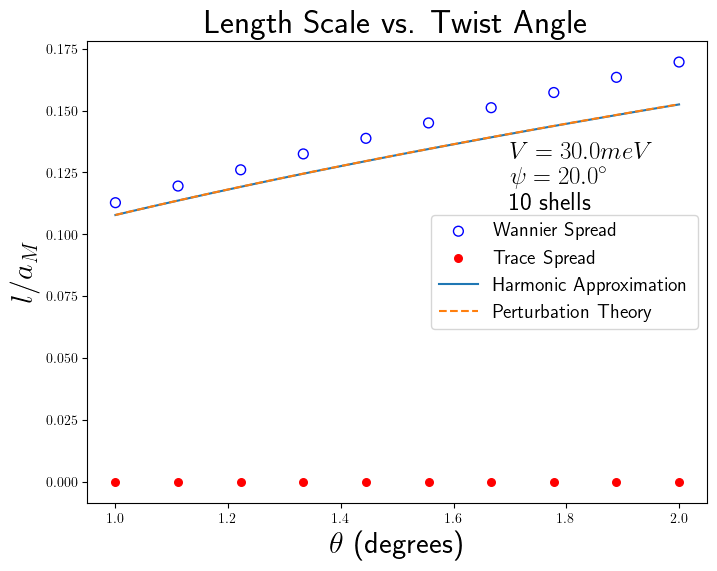

In [ ]:
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

fig = plt.figure(figsize=(8, 6))
plt.scatter(thetas, np.array(rW_values) / aMs0, facecolors='none', edgecolors='blue', s=50, label='Wannier Spread')
plt.scatter(thetas, np.array(l0_values) / aMs0, facecolors='red', edgecolors='red', s=30, label='Trace Spread')
plt.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs, label='Harmonic Approximation')
plt.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--', label='Perturbation Theory')
plt.xlabel(r'$\theta$ (degrees)', fontsize=22)
plt.ylabel(r'$l / a_M$', fontsize=22)
plt.title('Length Scale vs. Twist Angle', fontsize=24)
plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
plt.legend(fontsize=14)
plt.show()

## Hex Approach

In [ ]:
thetas = np.linspace(1.0, 2.0, 10)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
#rW_values = []
l0_valuesH = []
scale_W = 6.0

Nx = 300
Ny = 300

for th in tqdm(thetas):
    sys.theta_deg = th

    # x = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, Nx)
    # y = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, Ny)
    # X, Y = np.meshgrid(x, y)
    # k_points = sys.mesh_k_unit_cell(Nx=10, Ny=10)

    # fun = lambda xx, yy: xx**2 + yy**2
    # rW = np.sqrt( sys.integrate_wannier(fun, X, Y, k_points) )
    # rW_values.append(rW)

    k_points, shape, dkx, dky = sys.mesh_k_hex(Nx=10, Ny=10)

    _, integral = sys.integrate_trace_hex(k_points, shape, dkx, dky)
    l0 = np.sqrt(integral)
    l0_valuesH.append(l0)

100%|██████████| 10/10 [00:06<00:00,  1.60it/s]


<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\c'
<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\c'
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2972/1119190557.py:12: SyntaxWarning: invalid escape sequence '\p'
  plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2972/1119190557.py:12: SyntaxWarning: invalid escape sequence '\c'
  plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);


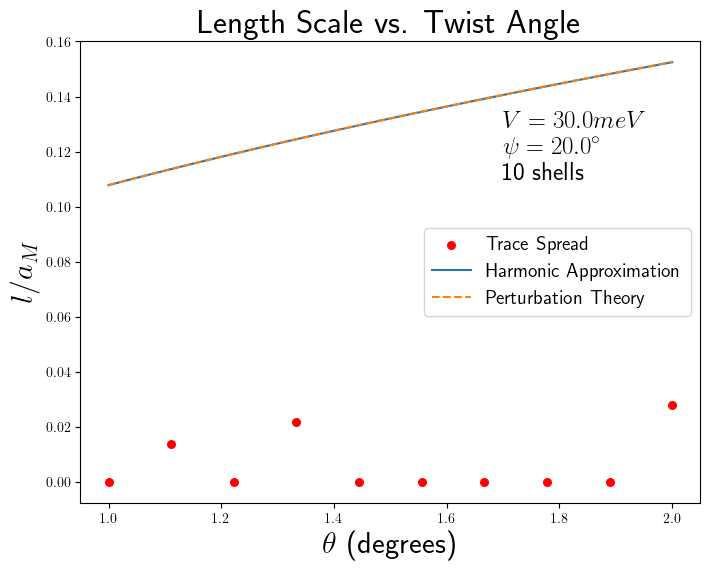

In [ ]:
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

fig = plt.figure(figsize=(8, 6))
#plt.scatter(thetas, np.array(rW_values) / aMs0, facecolors='none', edgecolors='blue', s=50, label='Wannier Spread')
plt.scatter(thetas, np.array(l0_valuesH) / aMs0, facecolors='red', edgecolors='red', s=30, label='Trace Spread')
plt.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs, label='Harmonic Approximation')
plt.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--', label='Perturbation Theory')
plt.xlabel(r'$\theta$ (degrees)', fontsize=22)
plt.ylabel(r'$l / a_M$', fontsize=22)
plt.title('Length Scale vs. Twist Angle', fontsize=24)
plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
plt.legend(fontsize=14)
plt.show()

In [ ]:
sys.V = 10.0

In [ ]:
thetas = np.linspace(1.0, 2.0, 10)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
rW_values = []
l0_values = []
scale_W = 8.0

Nx = 300
Ny = 300

for th in tqdm(thetas):
    sys.theta_deg = th

    x = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, Nx)
    y = np.linspace(-scale_W * sys.aM, scale_W * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    k_points = sys.mesh_k_unit_cell(Nx=15, Ny=15)

    fun = lambda xx, yy: xx**2 + yy**2
    rW = np.sqrt( sys.integrate_wannier(fun, X, Y, k_points) )
    rW_values.append(rW)

    _, integral, _, _ = sys.integrate_trace(KX, KY)
    l0 = np.sqrt(integral)
    l0_values.append(l0)

100%|██████████| 10/10 [14:20<00:00, 86.07s/it]


<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\c'
<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\c'
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_1066/266391091.py:12: SyntaxWarning: invalid escape sequence '\p'
  plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_1066/266391091.py:12: SyntaxWarning: invalid escape sequence '\c'
  plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);


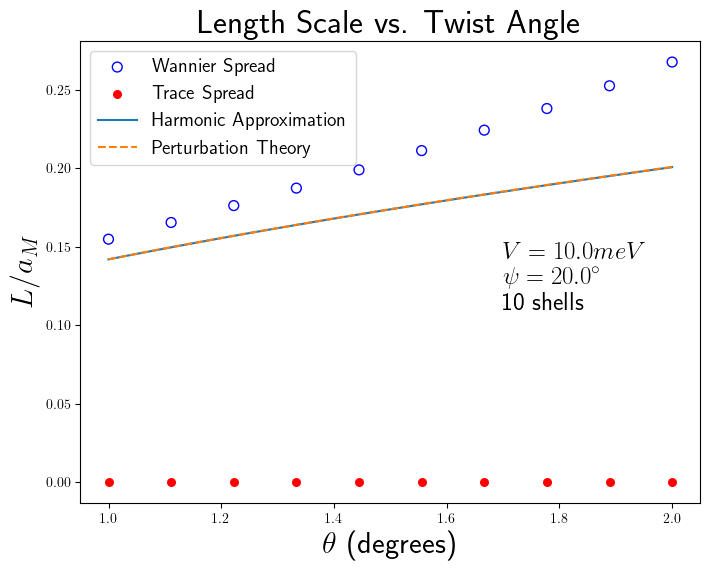

In [ ]:
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

fig = plt.figure(figsize=(8, 6))
plt.scatter(thetas, np.array(rW_values) / aMs0, facecolors='none', edgecolors='blue', s=50, label='Wannier Spread')
plt.scatter(thetas, np.array(l0_values) / aMs0, facecolors='red', edgecolors='red', s=30, label='Trace Spread')
plt.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs, label='Harmonic Approximation')
plt.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--', label='Perturbation Theory')
plt.xlabel(r'$\theta$ (degrees)', fontsize=22)
plt.ylabel(r'$L / a_M$', fontsize=22)
plt.title('Length Scale vs. Twist Angle', fontsize=24)
plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
plt.legend(fontsize=14)
plt.show()

In [ ]:
sys.psi_deg = 0.0
thetas = np.linspace(1.0, 2.0, 10)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
rW_values = []
l0_values = []

Nx = 200
Ny = 200

for th in tqdm(thetas):
    sys.theta_deg = th

    x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
    y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
    X, Y = np.meshgrid(x, y)
    k_points = sys.mesh_k_unit_cell()

    fun = lambda x, y: x**2 + y**2
    rW = np.sqrt( sys.integrate_wannier(fun, X, Y, k_points) )
    rW_values.append(rW)

    _, integral, _, _ = sys.integrate_trace(KX, KY)
    l0 = np.sqrt(integral)
    l0_values.append(l0)

100%|██████████| 10/10 [07:52<00:00, 47.26s/it]


<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\c'
<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\c'
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2450/266391091.py:12: SyntaxWarning: invalid escape sequence '\p'
  plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
/var/folders/9b/jbqq4fc95hg646f771gzxjdh0000gn/T/ipykernel_2450/266391091.py:12: SyntaxWarning: invalid escape sequence '\c'
  plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);


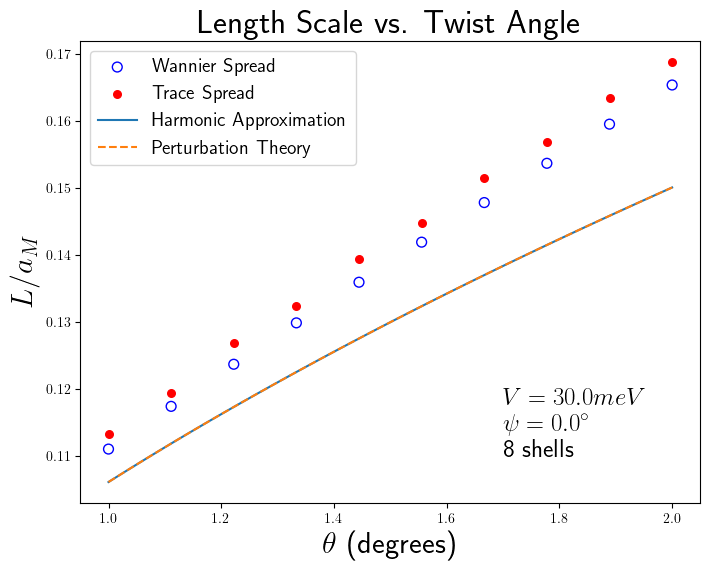

In [ ]:
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))
aMs = sys.a0 / (2 * np.sin(np.radians(thetas2 / 2)))

fig = plt.figure(figsize=(8, 6))
plt.scatter(thetas, np.array(rW_values) / aMs0, facecolors='none', edgecolors='blue', s=50, label='Wannier Spread')
plt.scatter(thetas, np.array(l0_values) / aMs0, facecolors='red', edgecolors='red', s=30, label='Trace Spread')
plt.plot(thetas2, utils.spread_harmonic_approx(aMs, sys.V, sys.psi) / aMs, label='Harmonic Approximation')
plt.plot(thetas2, utils.spread_perturbation(aMs, sys.V, sys.psi) / aMs, '--', label='Perturbation Theory')
plt.xlabel(r'$\theta$ (degrees)', fontsize=22)
plt.ylabel(r'$L / a_M$', fontsize=22)
plt.title('Length Scale vs. Twist Angle', fontsize=24)
plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
plt.legend(fontsize=14)
plt.show()

### Crosscheck $\psi \pm 120^\circ$

In [ ]:
thetas = np.linspace(1.0, 2.0, 5)
rW_values = []
l0_valuesA = []
l0_valuesB = []
l0_valuesC = []

Nx = 200
Ny = 200

for th in tqdm(thetas):
    sys.theta_deg = th
    
    sys.psi_deg = 20.0

    _, integral, _, _ = sys.integrate_trace(KX, KY)
    l0 = np.sqrt(integral)
    l0_valuesA.append(l0)

    sys.psi_deg = 20.0 + 120

    _, integral, _, _ = sys.integrate_trace(KX, KY)
    l0 = np.sqrt(integral)
    l0_valuesB.append(l0)

    sys.psi_deg = 20.0 - 120

    _, integral, _, _ = sys.integrate_trace(KX, KY)
    l0 = np.sqrt(integral)
    l0_valuesC.append(l0)

100%|██████████| 5/5 [11:20<00:00, 136.05s/it]


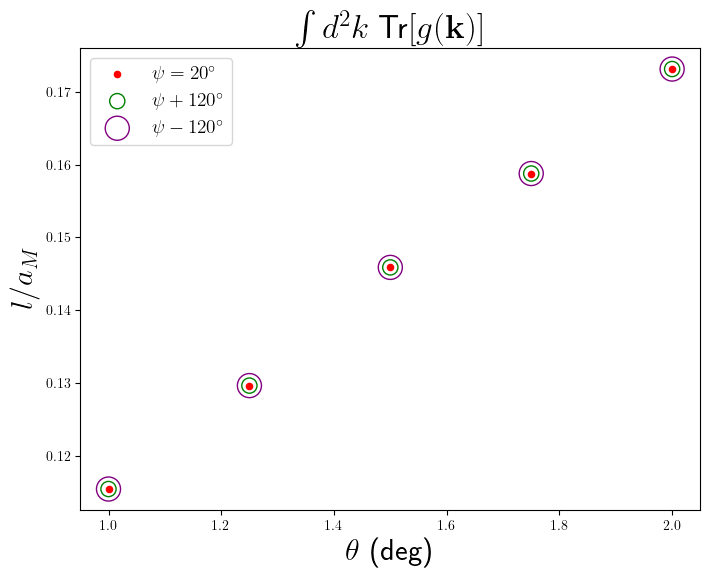

In [ ]:
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))

fig = plt.figure(figsize=(8, 6))
plt.scatter(thetas, np.array(l0_valuesA) / aMs0, facecolors='red', edgecolors='red', s=20, label=r'$\psi = 20^\circ$')
plt.scatter(thetas, np.array(l0_valuesB) / aMs0, facecolors='none', edgecolors='green', s=120, label=r'$\psi + 120^\circ$')
plt.scatter(thetas, np.array(l0_valuesC) / aMs0, facecolors='none', edgecolors='purple', s=300, label=r'$\psi - 120^\circ$')
plt.xlabel(r'$\theta$ (deg)', fontsize=22)
plt.ylabel(r'$L / a_M$', fontsize=22)
plt.title(r'$\int d^2 k\;\text{Tr}[g(\mathbf{k})]$', fontsize=24)
#plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
plt.legend(fontsize=14)
plt.show()

In [ ]:
thetas = np.linspace(1.0, 2.0, 10)
thetas2 = np.linspace(thetas[0], thetas[-1], 100)
rW_values = []
l0_valuesA = []
l0_valuesB = []
l0_valuesC = []

Vs = [10.0, 20.0, 30.0]

Nx = 200
Ny = 200

for th in tqdm(thetas):
    sys.theta_deg = th
    
    sys.V = Vs[0]
    _, integral, _, _ = sys.integrate_trace(KX, KY)
    l0 = np.sqrt(integral)
    l0_valuesA.append(l0)

    sys.V = Vs[1]
    _, integral, _, _ = sys.integrate_trace(KX, KY)
    l0 = np.sqrt(integral)
    l0_valuesB.append(l0)

    sys.V = Vs[2]
    _, integral, _, _ = sys.integrate_trace(KX, KY)
    l0 = np.sqrt(integral)
    l0_valuesC.append(l0)

100%|██████████| 10/10 [24:49<00:00, 148.96s/it]


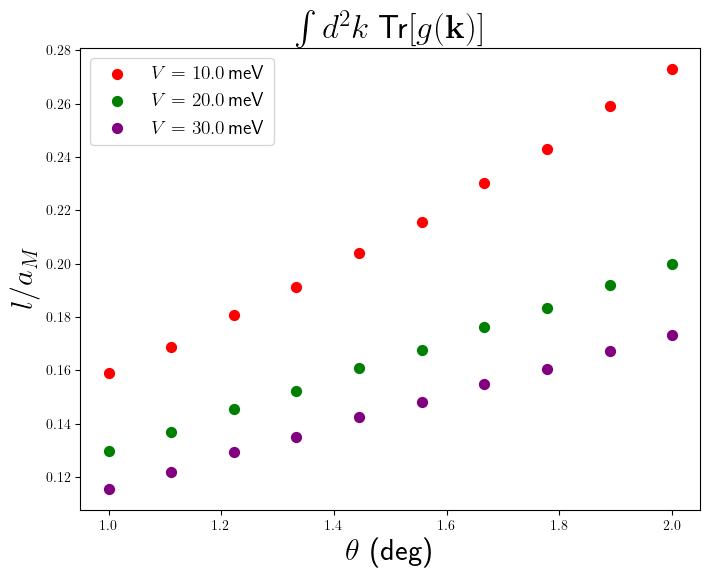

In [ ]:
aMs0 = sys.a0 / (2 * np.sin(np.radians(thetas / 2)))

fig = plt.figure(figsize=(8, 6))
plt.scatter(thetas, np.array(l0_valuesA) / aMs0, facecolors='red', edgecolors='red', s=50, label=r'$V = ' + str(Vs[0]) + r'\,\text{meV}$')
plt.scatter(thetas, np.array(l0_valuesB) / aMs0, facecolors='green', edgecolors='green', s=50, label=r'$V = ' + str(Vs[1]) + r'\,\text{meV}$')
plt.scatter(thetas, np.array(l0_valuesC) / aMs0, facecolors='purple', edgecolors='purple', s=50, label=r'$V = ' + str(Vs[2]) + r'\,\text{meV}$')
plt.xlabel(r'$\theta$ (deg)', fontsize=22)
plt.ylabel(r'$L / a_M$', fontsize=22)
plt.title(r'$\int d^2 k\;\text{Tr}[g(\mathbf{k})]$', fontsize=24)
#plt.text(1.7, 0.11, "$V = " + str(sys.V) + "meV$\n" + "$\psi = " + str(sys.psi_deg) + "^\circ$\n" + str(sys.n_shells) + " shells", fontsize=18);
plt.legend(fontsize=14)
plt.show()